In [2]:
# ===== CELL 0.2 | Imports =====
# Purpose: Import all required libraries in one place.

import os, json, random, platform, shutil, warnings
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import joblib
import sklearn

warnings.filterwarnings("ignore", category=FutureWarning)
sns.set_theme(style="whitegrid")
print("Imports done")

Imports done


In [3]:
# ===== CELL 0.3 | Library Versions =====
# Purpose: Record the environment versions for reproducibility.

print("Python      :", platform.python_version())
print("pandas      :", pd.__version__)
print("numpy       :", np.__version__)
print("scikit-learn:", sklearn.__version__)
print("seaborn     :", sns.__version__)

Python      : 3.13.16
pandas      : 2.3.3
numpy       : 2.1.3
scikit-learn: 1.6.1
seaborn     : 0.13.2


In [4]:
# ===== CELL 0.4 | Locate Dataset =====
# Purpose: Search /kaggle/input for student-mat.csv and student-por.csv.

def find_file(filename, root="/kaggle/input"):
    for dirpath, _, files in os.walk(root):
        if filename in files:
            return Path(dirpath) / filename
    return None

MAT_PATH = find_file("student-mat.csv")
POR_PATH = find_file("student-por.csv")

print("Math file      :", MAT_PATH)
print("Portuguese file:", POR_PATH)

if MAT_PATH is None:
    print("\nstudent-mat.csv not found. Available files:")
    for dirpath, _, files in os.walk("/kaggle/input"):
        for f in files:
            print("  ", Path(dirpath) / f)
    raise FileNotFoundError("Is the dataset added? Check the Input panel on the right.")

Math file      : /kaggle/input/datasets/rafianeyamat/student-performance-data-set-by-uci/Student Performance Data Set by UCI/student-mat.csv
Portuguese file: /kaggle/input/datasets/rafianeyamat/student-performance-data-set-by-uci/Student Performance Data Set by UCI/student-por.csv


In [5]:
# ===== CELL 0.5 | Configuration =====
# Purpose: Create output folders, fix the random seed, and set project-wide settings.

SEED = 42
random.seed(SEED)
np.random.seed(SEED)

BASE_DIR = Path("/kaggle/working")
CKPT_DIR = BASE_DIR / "checkpoints"
FIG_DIR  = BASE_DIR / "figures"
RES_DIR  = BASE_DIR / "results"
for d in (CKPT_DIR, FIG_DIR, RES_DIR):
    d.mkdir(parents=True, exist_ok=True)

# If True, all checkpoints are ignored and everything is recomputed
FORCE_RERUN = False

# Project-wide settings (later phases read from here)
TARGET     = "G3"
ALPHA      = 0.10      # 0.10 means a 90% prediction interval
N_FOLDS    = 5
TRAIN_FRAC, CALIB_FRAC, TEST_FRAC = 0.60, 0.20, 0.20

print("Folders ready:", CKPT_DIR, FIG_DIR, RES_DIR, sep="\n  ")
print("SEED =", SEED, "| FORCE_RERUN =", FORCE_RERUN)

Folders ready:
  /kaggle/working/checkpoints
  /kaggle/working/figures
  /kaggle/working/results
SEED = 42 | FORCE_RERUN = False


In [6]:
# ===== CELL 0.6 | Checkpoint Helpers =====
# Purpose: Save and load csv / json / joblib files through one consistent interface.

def ckpt_exists(name):
    """Return True if the checkpoint exists and FORCE_RERUN is off."""
    return (CKPT_DIR / name).exists() and not FORCE_RERUN

def ckpt_save(obj, name, index=False):
    """Save an object, choosing the method from the file extension."""
    path = CKPT_DIR / name
    if name.endswith(".csv"):
        obj.to_csv(path, index=index)
    elif name.endswith(".json"):
        with open(path, "w") as f:
            json.dump(obj, f, indent=2)
    elif name.endswith(".joblib"):
        joblib.dump(obj, path)
    else:
        raise ValueError("Supported: .csv, .json, .joblib")
    print(f"Saved: {name}")

def ckpt_load(name):
    """Load a previously saved checkpoint."""
    path = CKPT_DIR / name
    if name.endswith(".csv"):
        obj = pd.read_csv(path)
    elif name.endswith(".json"):
        with open(path) as f:
            obj = json.load(f)
    elif name.endswith(".joblib"):
        obj = joblib.load(path)
    else:
        raise ValueError("Supported: .csv, .json, .joblib")
    print(f"Loaded from checkpoint: {name}")
    return obj

def make_backup_zip(zip_name="checkpoints_backup"):
    """Zip the checkpoints folder so it can be downloaded as a backup."""
    out = shutil.make_archive(str(BASE_DIR / zip_name), "zip", CKPT_DIR)
    print("Backup zip:", out)

print("Helpers ready")

Helpers ready


In [7]:
# ===== CELL R.1 | Restore Checkpoints from Backup =====
# Purpose: Copy checkpoint files from the uploaded backup (zip or extracted folder) into CKPT_DIR.

import zipfile

def find_backup(root="/kaggle/input"):
    zip_path, folder = None, None
    for dirpath, _, files in os.walk(root):
        for f in files:
            if f.lower().startswith("checkpoints_backup") and f.lower().endswith(".zip"):
                zip_path = Path(dirpath) / f
        if "split_indices.json" in files and "df_clean.csv" in files:
            folder = Path(dirpath)
    return zip_path, folder

zip_path, folder = find_backup()

if folder is not None:
    for f in folder.iterdir():
        if f.is_file():
            shutil.copy(f, CKPT_DIR / f.name)
    print("Restored from folder:", folder)
elif zip_path is not None:
    with zipfile.ZipFile(zip_path) as z:
        z.extractall(CKPT_DIR)
    print("Restored from zip:", zip_path)
else:
    print("Backup not found. Check that the backup dataset is attached under Input.")
    for dirpath, _, files in os.walk("/kaggle/input"):
        for f in files:
            print("  ", Path(dirpath) / f)

Restored from folder: /kaggle/input/datasets/rafianeyamat/backup1


In [8]:
# ===== CELL 0.7 | Checkpoint Status =====
# Purpose: List all saved checkpoint files and their sizes.

def show_status():
    files = sorted(CKPT_DIR.glob("*"))
    if not files:
        print("No checkpoints found. Fresh start.")
        return
    print(f"{'File':35s} {'Size (KB)':>10s}")
    print("-" * 47)
    for f in files:
        print(f"{f.name:35s} {f.stat().st_size/1024:10.1f}")

show_status()

File                                 Size (KB)
-----------------------------------------------
best_params.json                           0.9
coverage_table.csv                         0.2
cv_results.csv                             1.2
df_clean.csv                              41.0
feature_sets.json                          1.6
intervals_A.csv                            4.9
intervals_B.csv                            5.0
intervals_C.csv                            5.0
model_A.joblib                           565.5
model_B.joblib                           433.2
model_C.joblib                           432.4
preds_A.csv                                4.7
preds_B.csv                                4.7
preds_C.csv                                4.7
q_values.json                              0.3
split_indices.json                         3.4
test_results.csv                           0.3


In [7]:
# ===== CELL 1.1 | Load Data =====
# Purpose: Load student-mat.csv and strip stray whitespace from text columns.

df = pd.read_csv(MAT_PATH, sep=None, engine="python")

# Remove accidental spaces/quotes in text values
text_cols = df.select_dtypes(include=["object", "string"]).columns
for c in text_cols:
    df[c] = df[c].astype(str).str.strip().str.strip('"')

print("Loaded:", MAT_PATH.name)
print("Shape :", df.shape)

Loaded: student-mat.csv
Shape : (395, 33)


In [8]:
# ===== CELL 1.2 | Shape, Dtypes, Head =====
# Purpose: Get a first look at the structure of the data.

print("Rows x Columns:", df.shape)
print("\nColumn types:")
print(df.dtypes.value_counts())
print("\nColumn list:")
print(df.columns.tolist())
df.head()

Rows x Columns: (395, 33)

Column types:
object    17
int64     16
Name: count, dtype: int64

Column list:
['school', 'sex', 'age', 'address', 'famsize', 'Pstatus', 'Medu', 'Fedu', 'Mjob', 'Fjob', 'reason', 'guardian', 'traveltime', 'studytime', 'failures', 'schoolsup', 'famsup', 'paid', 'activities', 'nursery', 'higher', 'internet', 'romantic', 'famrel', 'freetime', 'goout', 'Dalc', 'Walc', 'health', 'absences', 'G1', 'G2', 'G3']


,school,sex,age,address,famsize,Pstatus,Medu,Fedu,Mjob,Fjob,...,famrel,freetime,goout,Dalc,Walc,health,absences,G1,G2,G3
0,GP,F,18,U,GT3,A,4,4,at_home,teacher,...,4,3,4,1,1,3,6,5,6,6
1,GP,F,17,U,GT3,T,1,1,at_home,other,...,5,3,3,1,1,3,4,5,5,6
2,GP,F,15,U,LE3,T,1,1,at_home,other,...,4,3,2,2,3,3,10,7,8,10
3,GP,F,15,U,GT3,T,4,2,health,services,...,3,2,2,1,1,5,2,15,14,15
4,GP,F,16,U,GT3,T,3,3,other,other,...,4,3,2,1,2,5,4,6,10,10


In [9]:
# ===== CELL 1.3 | Missing Values and Duplicates =====
# Purpose: Check for empty cells and fully repeated rows.

missing = df.isna().sum()
print("Total missing values:", int(missing.sum()))
print("Columns with missing values:", missing[missing > 0].to_dict() or "none")

n_dupes = df.duplicated().sum()
print("\nDuplicate rows:", int(n_dupes))

Total missing values: 0
Columns with missing values: none

Duplicate rows: 0


In [10]:
# ===== CELL 1.4 | Invalid Value Check =====
# Purpose: Verify every column contains only allowed categories / valid numeric ranges.

YES_NO = ["yes", "no"]
CATEGORY_RULES = {
    "school":     ["GP", "MS"],
    "sex":        ["F", "M"],
    "address":    ["U", "R"],
    "famsize":    ["LE3", "GT3"],
    "Pstatus":    ["T", "A"],
    "Mjob":       ["teacher", "health", "services", "at_home", "other"],
    "Fjob":       ["teacher", "health", "services", "at_home", "other"],
    "reason":     ["home", "reputation", "course", "other"],
    "guardian":   ["mother", "father", "other"],
    "schoolsup":  YES_NO, "famsup": YES_NO, "paid": YES_NO,
    "activities": YES_NO, "nursery": YES_NO, "higher": YES_NO,
    "internet":   YES_NO, "romantic": YES_NO,
}

NUMERIC_RULES = {   # column: (min allowed, max allowed)
    "age": (15, 22),
    "Medu": (0, 4), "Fedu": (0, 4),
    "traveltime": (1, 4), "studytime": (1, 4), "failures": (0, 4),
    "famrel": (1, 5), "freetime": (1, 5), "goout": (1, 5),
    "Dalc": (1, 5), "Walc": (1, 5), "health": (1, 5),
    "absences": (0, 100),
    "G1": (0, 20), "G2": (0, 20), "G3": (0, 20),
}

problems = []

for col, allowed in CATEGORY_RULES.items():
    bad = set(df[col].unique()) - set(allowed)
    if bad:
        problems.append(f"{col}: unexpected categories {bad}")

for col, (lo, hi) in NUMERIC_RULES.items():
    n_bad = int(((df[col] < lo) | (df[col] > hi)).sum())
    if n_bad:
        problems.append(f"{col}: {n_bad} values outside [{lo}, {hi}]")

if problems:
    print("PROBLEMS FOUND:")
    for p in problems:
        print("  -", p)
else:
    print("All validation checks passed.")
    print(f"Checked {len(CATEGORY_RULES)} categorical and {len(NUMERIC_RULES)} numeric columns.")

All validation checks passed.
Checked 17 categorical and 16 numeric columns.


In [11]:
# ===== CELL 1.5 | Save Clean Data (Checkpoint) =====
# Purpose: Save the validated dataframe so later phases can load it instantly.

if ckpt_exists("df_clean.csv"):
    print("df_clean.csv already exists, skipping save.")
else:
    df_clean = df.copy()
    ckpt_save(df_clean, "df_clean.csv")

show_status()

Saved: df_clean.csv
File                                 Size (KB)
-----------------------------------------------
df_clean.csv                              41.0


Loaded from checkpoint: df_clean.csv


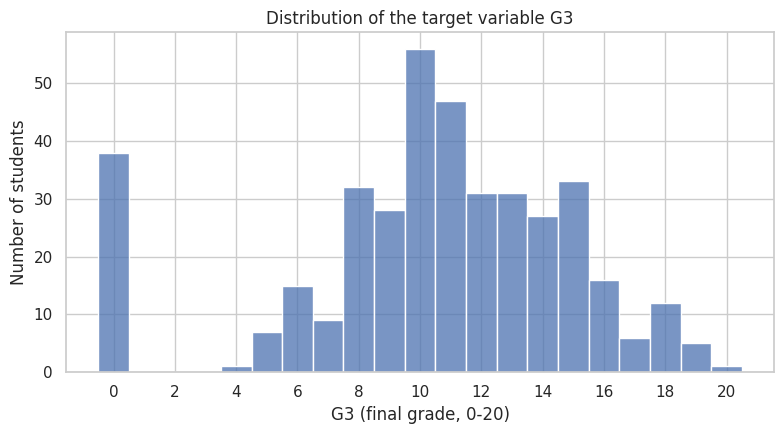

count    395.00
mean      10.42
std        4.58
min        0.00
25%        8.00
50%       11.00
75%       14.00
max       20.00
Name: G3, dtype: float64


In [12]:
# ===== CELL 2.1 | Load Clean Data + Target Histogram =====
# Purpose: Reload the checkpointed data and visualise the distribution of G3.

df = ckpt_load("df_clean.csv")

fig, ax = plt.subplots(figsize=(8, 4.5))
sns.histplot(df[TARGET], bins=21, binrange=(-0.5, 20.5), ax=ax)
ax.set_xlabel("G3 (final grade, 0-20)")
ax.set_ylabel("Number of students")
ax.set_title("Distribution of the target variable G3")
ax.set_xticks(range(0, 21, 2))
plt.tight_layout()
plt.savefig(FIG_DIR / "g3_hist.png", dpi=150, bbox_inches="tight")
plt.show()

print(df[TARGET].describe().round(2))

In [13]:
# ===== CELL 2.2 | Zero-Grade Students =====
# Purpose: Count students with G3 = 0 and see how they differ from the rest.

zero_mask = df[TARGET] == 0
n_zero = int(zero_mask.sum())
print(f"Students with G3 = 0: {n_zero} of {len(df)} ({100*n_zero/len(df):.1f}%)")

# Do zero-grade students also have zero in G1 / G2?
print("\nG1 and G2 for G3 = 0 students:")
print(df.loc[zero_mask, ["G1", "G2", "G3"]].describe().loc[["mean", "min", "max"]].round(2))

# Quick comparison with everyone else
print("\nAverage of key features (G3 = 0 vs G3 > 0):")
cols = ["absences", "failures", "studytime", "age"]
print(df.groupby(zero_mask.rename("G3_is_zero"))[cols].mean().round(2))

Students with G3 = 0: 38 of 395 (9.6%)

G1 and G2 for G3 = 0 students:
         G1     G2   G3
mean   7.53   4.66  0.0
min    4.00   0.00  0.0
max   12.00  10.00  0.0

Average of key features (G3 = 0 vs G3 > 0):
            absences  failures  studytime    age
G3_is_zero                                      
False           6.32      0.27       2.04  16.66
True            0.00      0.92       1.97  17.08


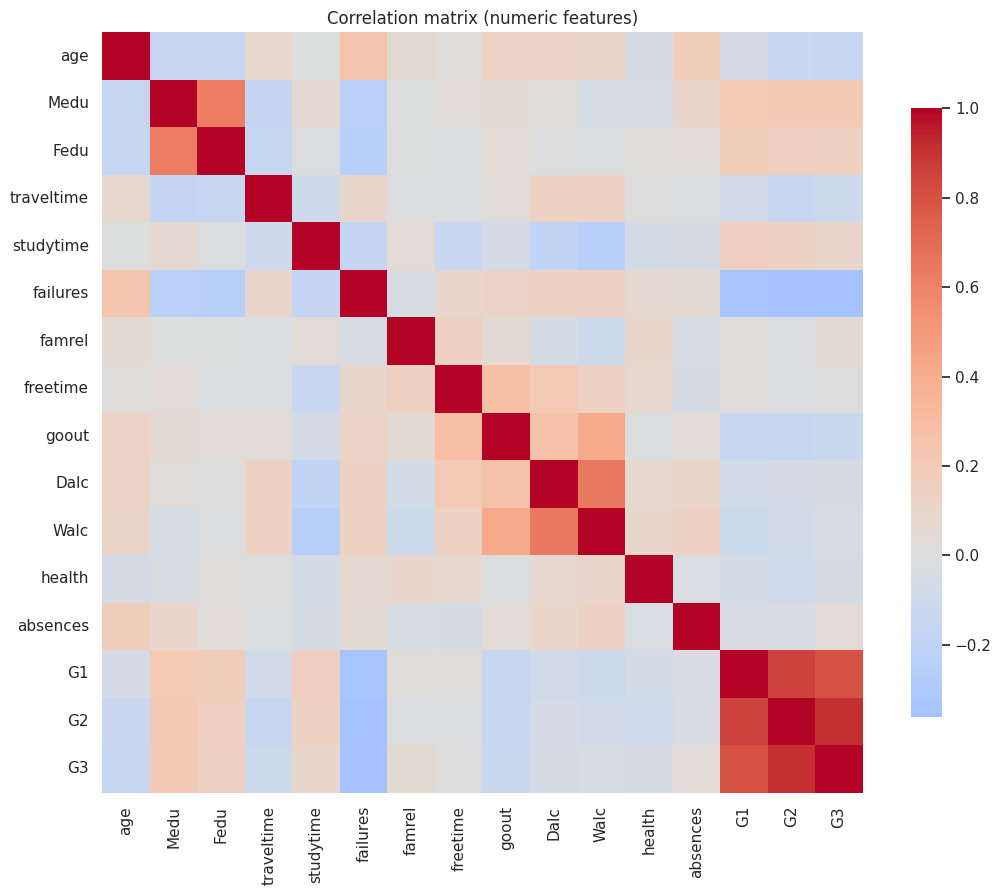

Correlation of each numeric feature with G3:
G2            0.90
G1            0.80
failures     -0.36
Medu          0.22
age          -0.16
Fedu          0.15
goout        -0.13
traveltime   -0.12
studytime     0.10
health       -0.06
Dalc         -0.05
Walc         -0.05
famrel        0.05
absences      0.03
freetime      0.01
Name: G3, dtype: float64


In [14]:
# ===== CELL 2.3 | Correlation Heatmap =====
# Purpose: Show how numeric features relate to each other and to G3.

num_df = df.select_dtypes(include="number")
corr = num_df.corr()

fig, ax = plt.subplots(figsize=(11, 9))
sns.heatmap(corr, cmap="coolwarm", center=0, annot=False, square=True,
            cbar_kws={"shrink": 0.8}, ax=ax)
ax.set_title("Correlation matrix (numeric features)")
plt.tight_layout()
plt.savefig(FIG_DIR / "corr.png", dpi=150, bbox_inches="tight")
plt.show()

print("Correlation of each numeric feature with G3:")
print(corr[TARGET].drop(TARGET).sort_values(key=abs, ascending=False).round(2))

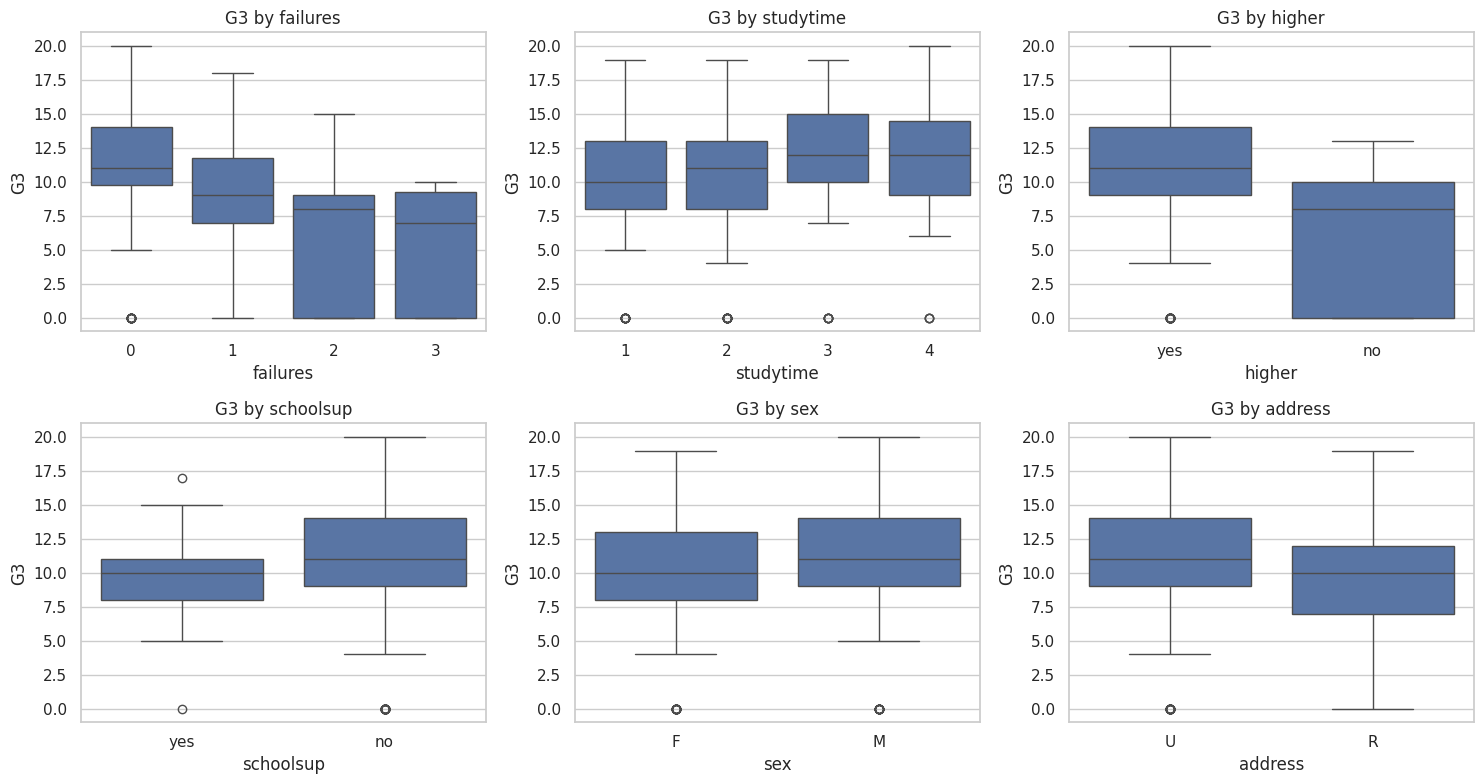

In [15]:
# ===== CELL 2.4 | Boxplots =====
# Purpose: Compare G3 across groups for a few key features.

box_cols = ["failures", "studytime", "higher", "schoolsup", "sex", "address"]

fig, axes = plt.subplots(2, 3, figsize=(15, 8))
for ax, col in zip(axes.ravel(), box_cols):
    sns.boxplot(data=df, x=col, y=TARGET, ax=ax)
    ax.set_title(f"G3 by {col}")
plt.tight_layout()
plt.savefig(FIG_DIR / "boxplots.png", dpi=150, bbox_inches="tight")
plt.show()

In [16]:
# ===== CELL 2.6 | Absences Check =====
# Purpose: Test whether zero-grade students distort the absences vs G3 relationship.

zero = df[TARGET] == 0
nz = df[~zero]

print("absences == 0 among G3 = 0 students:", int((df.loc[zero, "absences"] == 0).sum()), "of", int(zero.sum()))
print("absences == 0 among G3 > 0 students:", int((nz["absences"] == 0).sum()), "of", len(nz))
print("Corr(absences, G3), all students   :", round(df["absences"].corr(df[TARGET]), 2))
print("Corr(absences, G3), G3 > 0 only    :", round(nz["absences"].corr(nz[TARGET]), 2))

absences == 0 among G3 = 0 students: 38 of 38
absences == 0 among G3 > 0 students: 77 of 357
Corr(absences, G3), all students   : 0.03
Corr(absences, G3), G3 > 0 only    : -0.21


In [9]:
# ===== CELL 3.1 | Column Type Lists =====
# Purpose: Split the input columns into categorical and numeric lists.

df = ckpt_load("df_clean.csv")

EXCLUDED = [TARGET, "G1", "G2", "absences"]   # G1/G2 are added back per scenario; absences is never used
base_cols = [c for c in df.columns if c not in EXCLUDED]

CAT_COLS = [c for c in base_cols if df[c].dtype == "object" or str(df[c].dtype) == "string"]
NUM_COLS = [c for c in base_cols if c not in CAT_COLS]

print(f"Base features : {len(base_cols)}")
print(f"Categorical   : {len(CAT_COLS)} -> {CAT_COLS}")
print(f"Numeric       : {len(NUM_COLS)} -> {NUM_COLS}")

Loaded from checkpoint: df_clean.csv
Base features : 29
Categorical   : 17 -> ['school', 'sex', 'address', 'famsize', 'Pstatus', 'Mjob', 'Fjob', 'reason', 'guardian', 'schoolsup', 'famsup', 'paid', 'activities', 'nursery', 'higher', 'internet', 'romantic']
Numeric       : 12 -> ['age', 'Medu', 'Fedu', 'traveltime', 'studytime', 'failures', 'famrel', 'freetime', 'goout', 'Dalc', 'Walc', 'health']


In [11]:
# ===== CELL 3.2 | Scenario Feature Sets =====
# Purpose: Define which features each scenario (A, B, C) is allowed to use.

SCENARIOS = {
    "A": {"cat": CAT_COLS, "num": NUM_COLS},
    "B": {"cat": CAT_COLS, "num": NUM_COLS + ["G1"]},
    "C": {"cat": CAT_COLS, "num": NUM_COLS + ["G1", "G2"]},
}

# Safety checks: no leakage, no duplicates, correct sizes
for name, s in SCENARIOS.items():
    feats = s["cat"] + s["num"]
    assert TARGET not in feats, "Target leaked into features"
    assert "absences" not in feats, "absences should be excluded"
    assert len(feats) == len(set(feats)), "Duplicate feature"
    print(f"Scenario {name}: {len(feats)} features "
          f"({len(s['cat'])} categorical + {len(s['num'])} numeric)")

print("\nExtra features vs A:",
      {n: sorted(set(s['cat'] + s['num']) - set(CAT_COLS + NUM_COLS)) for n, s in SCENARIOS.items()})

Scenario A: 29 features (17 categorical + 12 numeric)
Scenario B: 30 features (17 categorical + 13 numeric)
Scenario C: 31 features (17 categorical + 14 numeric)

Extra features vs A: {'A': [], 'B': ['G1'], 'C': ['G1', 'G2']}


In [12]:
# ===== CELL 3.3 | Save Feature Sets (Checkpoint) =====
# Purpose: Persist the scenario definitions so every later phase uses identical features.

if ckpt_exists("feature_sets.json"):
    SCENARIOS = ckpt_load("feature_sets.json")
    print("Scenarios restored:", list(SCENARIOS.keys()))
else:
    ckpt_save(SCENARIOS, "feature_sets.json")

show_status()

Loaded from checkpoint: feature_sets.json
Scenarios restored: ['A', 'B', 'C']
File                                 Size (KB)
-----------------------------------------------
best_params.json                           0.9
coverage_table.csv                         0.2
cv_results.csv                             1.2
df_clean.csv                              41.0
feature_sets.json                          1.6
intervals_A.csv                            4.9
intervals_B.csv                            5.0
intervals_C.csv                            5.0
model_A.joblib                           565.5
model_B.joblib                           433.2
model_C.joblib                           432.4
preds_A.csv                                4.7
preds_B.csv                                4.7
preds_C.csv                                4.7
q_values.json                              0.3
split_indices.json                         3.4
test_results.csv                           0.3


In [13]:
# ===== CELL 4.1 | Train / Calibration / Test Split =====
# Purpose: Create a stratified 60/20/20 split (stratified on G3 = 0) and checkpoint the row indices.

from sklearn.model_selection import train_test_split

df = ckpt_load("df_clean.csv")

if ckpt_exists("split_indices.json"):
    split_idx = ckpt_load("split_indices.json")
else:
    strata = (df[TARGET] == 0).astype(int)          # 1 = zero-grade student, 0 = everyone else

    # Step 1: separate train from (calibration + test)
    train_idx, temp_idx = train_test_split(
        df.index, test_size=CALIB_FRAC + TEST_FRAC,
        stratify=strata, random_state=SEED)

    # Step 2: split the remainder 50/50 into calibration and test
    calib_idx, test_idx = train_test_split(
        temp_idx, test_size=TEST_FRAC / (CALIB_FRAC + TEST_FRAC),
        stratify=strata.loc[temp_idx], random_state=SEED)

    split_idx = {
        "train": sorted(int(i) for i in train_idx),
        "calib": sorted(int(i) for i in calib_idx),
        "test":  sorted(int(i) for i in test_idx),
    }
    ckpt_save(split_idx, "split_indices.json")

df_train = df.loc[split_idx["train"]]
df_calib = df.loc[split_idx["calib"]]
df_test  = df.loc[split_idx["test"]]
print("Train / Calib / Test:", len(df_train), "/", len(df_calib), "/", len(df_test))

Loaded from checkpoint: df_clean.csv
Loaded from checkpoint: split_indices.json
Train / Calib / Test: 237 / 79 / 79


In [14]:
# ===== CELL 4.2 | Verify Split =====
# Purpose: Confirm sizes, no overlap between sets, and similar target distributions.

sets = {"train": df_train, "calib": df_calib, "test": df_test}

# No row may appear in two sets, and together they must cover all rows
all_idx = [i for s in sets.values() for i in s.index]
assert len(all_idx) == len(set(all_idx)) == len(df), "Overlap or missing rows"

summary = pd.DataFrame({
    name: {
        "rows": len(s),
        "share_%": round(100 * len(s) / len(df), 1),
        "G3 = 0 count": int((s[TARGET] == 0).sum()),
        "G3 = 0 share_%": round(100 * (s[TARGET] == 0).mean(), 1),
        "G3 mean": round(s[TARGET].mean(), 2),
        "G3 std": round(s[TARGET].std(), 2),
    } for name, s in sets.items()
}).T
print("All checks passed: no overlap, all 395 rows assigned.\n")
print(summary)

All checks passed: no overlap, all 395 rows assigned.

        rows  share_%  G3 = 0 count  G3 = 0 share_%  G3 mean  G3 std
train  237.0     60.0          23.0             9.7    10.50    4.63
calib   79.0     20.0           8.0            10.1    10.30    4.63
test    79.0     20.0           7.0             8.9    10.27    4.44


In [22]:
# ===== CELL 4.3 | Backup Zip =====
# Purpose: Zip all checkpoints so they can be downloaded as a safety copy.

make_backup_zip("checkpoints_backup")
show_status()

Backup zip: /kaggle/working/checkpoints_backup.zip
File                                 Size (KB)
-----------------------------------------------
df_clean.csv                              41.0
feature_sets.json                          1.6
split_indices.json                         3.4


In [15]:
# ===== CELL 5.1 | Preprocessor Builder =====
# Purpose: Build the encoding + scaling step for a given scenario.

from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder, StandardScaler

def build_preprocessor(scenario):
    """One-hot encode categorical columns, standardise numeric columns."""
    cols = SCENARIOS[scenario]
    return ColumnTransformer([
        ("cat", OneHotEncoder(handle_unknown="ignore"), cols["cat"]),
        ("num", StandardScaler(), cols["num"]),
    ])

print("build_preprocessor ready")

build_preprocessor ready


In [16]:
# ===== CELL 5.2 | Pipeline and X/y Helpers =====
# Purpose: Attach any model to the preprocessor, and select X and y for a scenario.

from sklearn.pipeline import Pipeline

def make_pipeline(model, scenario):
    """Preprocessing + model in one object (fitted only on whatever data fit() receives)."""
    return Pipeline([("pre", build_preprocessor(scenario)), ("model", model)])

def get_xy(df_part, scenario):
    """Return the scenario's feature columns (X) and the target (y)."""
    cols = SCENARIOS[scenario]["cat"] + SCENARIOS[scenario]["num"]
    return df_part[cols], df_part[TARGET]

print("make_pipeline and get_xy ready")

make_pipeline and get_xy ready


In [25]:
# ===== CELL 5.3 | Sanity Check =====
# Purpose: Confirm the preprocessor works, produces no NaN, and learns only from train data.

from sklearn.linear_model import Ridge

for sc in ["A", "B", "C"]:
    X_tr, y_tr = get_xy(df_train, sc)
    X_ca, _    = get_xy(df_calib, sc)
    pre = build_preprocessor(sc).fit(X_tr)
    Xt, Xc = pre.transform(X_tr), pre.transform(X_ca)
    print(f"Scenario {sc}: input cols = {X_tr.shape[1]}, "
          f"after encoding = {Xt.shape[1]}, NaN = {int(np.isnan(Xt).sum())}")

# Scaler statistics must come from train only
scaler = pre.named_transformers_["num"]
print("\nScaler mean for 'age' (train only):",
      round(float(scaler.mean_[SCENARIOS['C']['num'].index('age')]), 3))
print("Train mean of 'age'               :", round(float(df_train['age'].mean()), 3))
print("Full-data mean of 'age' (not used):", round(float(df['age'].mean()), 3))

# One quick end-to-end run to make sure the pipeline fits and predicts
p = make_pipeline(Ridge(alpha=1.0), "A").fit(*get_xy(df_train, "A"))
print("\nPipeline test prediction shape:", p.predict(get_xy(df_calib, "A")[0]).shape)

Scenario A: input cols = 29, after encoding = 55, NaN = 0
Scenario B: input cols = 30, after encoding = 56, NaN = 0
Scenario C: input cols = 31, after encoding = 57, NaN = 0

Scaler mean for 'age' (train only): 16.696
Train mean of 'age'               : 16.696
Full-data mean of 'age' (not used): 16.696

Pipeline test prediction shape: (79,)


In [26]:
# ===== CELL 5.3b | Stricter Leakage Check =====
# Purpose: Compare scaler means with train-only vs full-data means at 6 decimals, on all numeric columns.

num = SCENARIOS["C"]["num"]
cmp = pd.DataFrame({
    "scaler_mean": scaler.mean_,
    "train_mean":  df_train[num].mean().values,
    "full_mean":   df[num].mean().values,
}, index=num).round(6)
cmp["scaler==train"] = np.isclose(cmp["scaler_mean"], cmp["train_mean"])
print(cmp)

            scaler_mean  train_mean  full_mean  scaler==train
age           16.696203   16.696203  16.696203           True
Medu           2.772152    2.772152   2.749367           True
Fedu           2.544304    2.544304   2.521519           True
traveltime     1.464135    1.464135   1.448101           True
studytime      2.021097    2.021097   2.035443           True
failures       0.350211    0.350211   0.334177           True
famrel         3.911392    3.911392   3.944304           True
freetime       3.210970    3.210970   3.235443           True
goout          3.092827    3.092827   3.108861           True
Dalc           1.476793    1.476793   1.481013           True
Walc           2.244726    2.244726   2.291139           True
health         3.573840    3.573840   3.554430           True
G1            10.978903   10.978903  10.908861           True
G2            10.755274   10.755274  10.713924           True


In [17]:
# ===== CELL 6.1 | Define Models =====
# Purpose: Create the baseline and the two candidate models.

from sklearn.dummy import DummyRegressor
from sklearn.linear_model import Ridge
from sklearn.ensemble import RandomForestRegressor

def get_models():
    """Fresh, unfitted model objects (called each time so nothing carries over)."""
    return {
        "Baseline (mean)": DummyRegressor(strategy="mean"),
        "Ridge":           Ridge(alpha=1.0),
        "RandomForest":    RandomForestRegressor(
                               n_estimators=300, min_samples_leaf=3,
                               random_state=SEED, n_jobs=-1),
    }

print("Models:", list(get_models().keys()))

Models: ['Baseline (mean)', 'Ridge', 'RandomForest']


In [18]:
# ===== CELL 6.2 | Cross-Validation Function =====
# Purpose: Run 5-fold CV on the training set and return mean and std of MAE, RMSE, R2.

from sklearn.model_selection import KFold, cross_validate

def run_cv(model, scenario):
    X_tr, y_tr = get_xy(df_train, scenario)
    cv = KFold(n_splits=N_FOLDS, shuffle=True, random_state=SEED)
    s = cross_validate(
        make_pipeline(model, scenario), X_tr, y_tr, cv=cv,
        scoring={"mae": "neg_mean_absolute_error",
                 "rmse": "neg_root_mean_squared_error",
                 "r2": "r2"})
    return {
        "MAE_mean":  -s["test_mae"].mean(),  "MAE_std":  s["test_mae"].std(),
        "RMSE_mean": -s["test_rmse"].mean(), "RMSE_std": s["test_rmse"].std(),
        "R2_mean":   s["test_r2"].mean(),    "R2_std":   s["test_r2"].std(),
    }

print("run_cv ready")

run_cv ready


In [19]:
# ===== CELL 6.3 | Run CV (Checkpoint) =====
# Purpose: Cross-validate every model on every scenario; load from checkpoint if already done.

if ckpt_exists("cv_results.csv"):
    cv_results = ckpt_load("cv_results.csv")
else:
    rows = []
    for sc in ["A", "B", "C"]:
        for name, model in get_models().items():
            res = run_cv(model, sc)
            rows.append({"Scenario": sc, "Model": name, **res})
            print(f"Scenario {sc} | {name:16s} MAE = {res['MAE_mean']:.2f}")
    cv_results = pd.DataFrame(rows)
    ckpt_save(cv_results, "cv_results.csv")

Loaded from checkpoint: cv_results.csv


In [30]:
# ===== CELL 6.4 | Results Table =====
# Purpose: Show CV results as "mean ± std" and save a copy to results/.

def pm(m, s):
    return f"{m:.2f} ± {s:.2f}"

table = pd.DataFrame({
    "Scenario": cv_results["Scenario"],
    "Model":    cv_results["Model"],
    "MAE":  [pm(a, b) for a, b in zip(cv_results.MAE_mean,  cv_results.MAE_std)],
    "RMSE": [pm(a, b) for a, b in zip(cv_results.RMSE_mean, cv_results.RMSE_std)],
    "R2":   [pm(a, b) for a, b in zip(cv_results.R2_mean,   cv_results.R2_std)],
})
table.to_csv(RES_DIR / "cv_table.csv", index=False)
print(table.to_string(index=False))

Scenario           Model         MAE        RMSE           R2
       A Baseline (mean) 3.46 ± 0.46 4.60 ± 0.48 -0.01 ± 0.00
       A           Ridge 3.70 ± 0.53 4.91 ± 0.56 -0.15 ± 0.16
       A    RandomForest 3.37 ± 0.52 4.48 ± 0.44  0.03 ± 0.12
       B Baseline (mean) 3.46 ± 0.46 4.60 ± 0.48 -0.01 ± 0.00
       B           Ridge 2.37 ± 0.17 3.14 ± 0.23  0.51 ± 0.12
       B    RandomForest 2.05 ± 0.13 2.81 ± 0.18  0.61 ± 0.08
       C Baseline (mean) 3.46 ± 0.46 4.60 ± 0.48 -0.01 ± 0.00
       C           Ridge 1.49 ± 0.26 2.17 ± 0.37  0.76 ± 0.08
       C    RandomForest 1.30 ± 0.10 2.03 ± 0.22  0.79 ± 0.07


In [31]:
# ===== CELL 6.5 | Backup Zip =====
# Purpose: Refresh the backup so it includes the Phase 6 results.

make_backup_zip("checkpoints_backup")
show_status()

Backup zip: /kaggle/working/checkpoints_backup.zip
File                                 Size (KB)
-----------------------------------------------
cv_results.csv                             1.2
df_clean.csv                              41.0
feature_sets.json                          1.6
split_indices.json                         3.4


In [20]:
# ===== CELL 7.1 | Parameter Grids =====
# Purpose: Define the small search spaces for Ridge and Random Forest.

PARAM_GRIDS = {
    "Ridge": {
        "model__alpha": [0.1, 1, 10, 30, 100, 300],
    },
    "RandomForest": {
        "model__max_depth":        [3, 6, None],
        "model__min_samples_leaf": [1, 3, 5, 10],
        "model__max_features":     [0.3, 0.6, 1.0],
    },
}

n_rf = np.prod([len(v) for v in PARAM_GRIDS["RandomForest"].values()])
print(f"Ridge combos: {len(PARAM_GRIDS['Ridge']['model__alpha'])} | RandomForest combos: {n_rf}")
print(f"Total fits: {3 * (6 + n_rf) * N_FOLDS}")

Ridge combos: 6 | RandomForest combos: 36
Total fits: 630


In [21]:
# ===== CELL 7.2 | GridSearchCV (Checkpoint) =====
# Purpose: Tune Ridge and Random Forest per scenario on the training set only; save best params.

from sklearn.model_selection import GridSearchCV

if ckpt_exists("best_params.json"):
    best_params = ckpt_load("best_params.json")
else:
    best_params = {}
    cv = KFold(n_splits=N_FOLDS, shuffle=True, random_state=SEED)   # same folds as Phase 6
    base_models = {"Ridge": Ridge(), 
                   "RandomForest": RandomForestRegressor(n_estimators=300, random_state=SEED, n_jobs=-1)}

    for sc in ["A", "B", "C"]:
        X_tr, y_tr = get_xy(df_train, sc)
        best_params[sc] = {}
        for name, model in base_models.items():
            gs = GridSearchCV(make_pipeline(model, sc), PARAM_GRIDS[name],
                              scoring="neg_mean_absolute_error", cv=cv,
                              refit=False, n_jobs=1)
            gs.fit(X_tr, y_tr)
            params = {k.replace("model__", ""): v for k, v in gs.best_params_.items()}
            best_params[sc][name] = {"params": params, "cv_mae": float(-gs.best_score_)}
            print(f"Scenario {sc} | {name:12s} best MAE = {-gs.best_score_:.3f} | {params}")

    ckpt_save(best_params, "best_params.json")

Loaded from checkpoint: best_params.json


In [34]:
# ===== CELL 7.3 | Tuned vs Default =====
# Purpose: Compare default CV MAE (Phase 6) with tuned CV MAE for each scenario and model.

rows = []
for sc in ["A", "B", "C"]:
    for name in ["Ridge", "RandomForest"]:
        default = cv_results[(cv_results.Scenario == sc) & (cv_results.Model == name)]["MAE_mean"].iloc[0]
        tuned = best_params[sc][name]["cv_mae"]
        rows.append({"Scenario": sc, "Model": name,
                     "Default MAE": round(default, 3), "Tuned MAE": round(tuned, 3),
                     "Gain": round(default - tuned, 3),
                     "Best params": best_params[sc][name]["params"]})
tuning_table = pd.DataFrame(rows)
tuning_table.drop(columns="Best params").to_csv(RES_DIR / "tuning_table.csv", index=False)
print(tuning_table.to_string(index=False))

Scenario        Model  Default MAE  Tuned MAE  Gain                                                      Best params
       A        Ridge        3.704      3.292 0.412                                                   {'alpha': 300}
       A RandomForest        3.370      3.252 0.118 {'max_depth': None, 'max_features': 0.3, 'min_samples_leaf': 10}
       B        Ridge        2.373      2.118 0.255                                                    {'alpha': 30}
       B RandomForest        2.051      1.993 0.058     {'max_depth': 3, 'max_features': 1.0, 'min_samples_leaf': 1}
       C        Ridge        1.495      1.411 0.084                                                    {'alpha': 30}
       C RandomForest        1.298      1.265 0.034     {'max_depth': 3, 'max_features': 1.0, 'min_samples_leaf': 1}


In [35]:
# ===== CELL 7.4 | Backup Zip =====
# Purpose: Refresh the backup so it includes best_params.json.

make_backup_zip("checkpoints_backup")
show_status()

Backup zip: /kaggle/working/checkpoints_backup.zip
File                                 Size (KB)
-----------------------------------------------
best_params.json                           0.9
cv_results.csv                             1.2
df_clean.csv                              41.0
feature_sets.json                          1.6
split_indices.json                         3.4


In [22]:
# ===== CELL 8.1 | Final Model Builder =====
# Purpose: Build each model with its tuned hyperparameters and pick the model per scenario by CV rule.

from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

def build_final_model(name, scenario):
    if name == "Baseline (mean)":
        return DummyRegressor(strategy="mean")
    params = best_params[scenario][name]["params"]
    if name == "Ridge":
        return Ridge(**params)
    if name == "RandomForest":
        return RandomForestRegressor(n_estimators=300, random_state=SEED, n_jobs=-1, **params)
    raise ValueError(name)

# Rule fixed in Phase 7: lowest tuned CV MAE per scenario
SELECTED = {sc: min(best_params[sc], key=lambda n: best_params[sc][n]["cv_mae"])
            for sc in ["A", "B", "C"]}
print("Selected model per scenario:", SELECTED)

Selected model per scenario: {'A': 'RandomForest', 'B': 'RandomForest', 'C': 'RandomForest'}


In [24]:
# ===== CELL 8.2 | Fit and Predict (Checkpoint) =====
# Purpose: Fit the selected model on train only; save calib + test predictions and the fitted pipeline.

for sc in ["A", "B", "C"]:
    model_file, preds_file = f"model_{sc}.joblib", f"preds_{sc}.csv"
    if ckpt_exists(model_file) and ckpt_exists(preds_file):
        print(f"Scenario {sc}: already done, skipping.")
        continue

    X_tr, y_tr = get_xy(df_train, sc)
    pipe = make_pipeline(build_final_model(SELECTED[sc], sc), sc).fit(X_tr, y_tr)

    parts = []
    for set_name, part in [("calib", df_calib), ("test", df_test)]:
        X, y = get_xy(part, sc)
        parts.append(pd.DataFrame({"row_id": part.index, "set": set_name,
                                   "y_true": y.values, "y_pred": pipe.predict(X)}))
    ckpt_save(pipe, model_file)
    ckpt_save(pd.concat(parts, ignore_index=True), preds_file)

show_status()

Scenario A: already done, skipping.
Scenario B: already done, skipping.
Scenario C: already done, skipping.
File                                 Size (KB)
-----------------------------------------------
best_params.json                           0.9
coverage_table.csv                         0.2
cv_results.csv                             1.2
df_clean.csv                              41.0
feature_sets.json                          1.6
intervals_A.csv                            4.9
intervals_B.csv                            5.0
intervals_C.csv                            5.0
model_A.joblib                           565.5
model_B.joblib                           433.2
model_C.joblib                           432.4
preds_A.csv                                4.7
preds_B.csv                                4.7
preds_C.csv                                4.7
q_values.json                              0.3
split_indices.json                         3.4
test_results.csv                           0.

In [25]:
# ===== CELL 8.3 | Test Results Table =====
# Purpose: Report test MAE, RMSE, R2 for baseline, Ridge and Random Forest in each scenario.

def get_metrics(y, p):
    return {"MAE": mean_absolute_error(y, p),
            "RMSE": np.sqrt(mean_squared_error(y, p)),
            "R2": r2_score(y, p)}

rows = []
for sc in ["A", "B", "C"]:
    X_tr, y_tr = get_xy(df_train, sc)
    X_te, y_te = get_xy(df_test, sc)
    saved = pd.read_csv(CKPT_DIR / f"preds_{sc}.csv")
    saved_test = saved[saved["set"] == "test"]

    for name in ["Baseline (mean)", "Ridge", "RandomForest"]:
        if name == SELECTED[sc]:
            pred = saved_test["y_pred"].values            # identical to the checkpointed predictions
            assert np.allclose(saved_test["y_true"].values, y_te.values)
        else:
            pred = make_pipeline(build_final_model(name, sc), sc).fit(X_tr, y_tr).predict(X_te)
        rows.append({"Scenario": sc, "Model": name,
                     "Selected": "yes" if name == SELECTED[sc] else "",
                     **{k: round(v, 3) for k, v in get_metrics(y_te, pred).items()}})

test_results = pd.DataFrame(rows)
ckpt_save(test_results, "test_results.csv")
test_results.to_csv(RES_DIR / "test_results.csv", index=False)
print(test_results.to_string(index=False))

Saved: test_results.csv
Scenario           Model Selected   MAE  RMSE     R2
       A Baseline (mean)          3.361 4.418 -0.003
       A           Ridge          2.965 3.940  0.202
       A    RandomForest      yes 2.950 3.926  0.208
       B Baseline (mean)          3.361 4.418 -0.003
       B           Ridge          1.983 2.731  0.617
       B    RandomForest      yes 2.122 2.927  0.560
       C Baseline (mean)          3.361 4.418 -0.003
       C           Ridge          1.311 1.890  0.816
       C    RandomForest      yes 1.214 1.806  0.832


In [39]:
# ===== CELL 8.4 | Bootstrap Confidence Intervals =====
# Purpose: 95% CI for test MAE of the selected model, and for its improvement over the mean baseline.

rng = np.random.default_rng(SEED)
B = 5000
rows = []
for sc in ["A", "B", "C"]:
    saved = pd.read_csv(CKPT_DIR / f"preds_{sc}.csv")
    t = saved[saved["set"] == "test"]
    y, p = t["y_true"].values, t["y_pred"].values
    base_pred = df_train[TARGET].mean()

    err_model = np.abs(y - p)
    err_base  = np.abs(y - base_pred)
    idx = rng.integers(0, len(y), size=(B, len(y)))          # resample test rows with replacement

    mae_model = err_model[idx].mean(axis=1)
    improve   = (err_base - err_model)[idx].mean(axis=1)     # > 0 means model is better than baseline
    lo, hi = np.percentile(mae_model, [2.5, 97.5])
    ilo, ihi = np.percentile(improve, [2.5, 97.5])

    rows.append({"Scenario": sc, "Model": SELECTED[sc],
                 "Test MAE": round(err_model.mean(), 2),
                 "MAE 95% CI": f"[{lo:.2f}, {hi:.2f}]",
                 "Baseline MAE": round(err_base.mean(), 2),
                 "Improvement": round(err_base.mean() - err_model.mean(), 2),
                 "Improvement 95% CI": f"[{ilo:.2f}, {ihi:.2f}]",
                 "CI excludes 0": bool(ilo > 0)})

boot_table = pd.DataFrame(rows)
boot_table.to_csv(RES_DIR / "bootstrap_ci.csv", index=False)
print(boot_table.to_string(index=False))

Scenario        Model  Test MAE   MAE 95% CI  Baseline MAE  Improvement Improvement 95% CI  CI excludes 0
       A RandomForest      2.95 [2.39, 3.54]          3.36         0.41       [0.19, 0.64]           True
       B RandomForest      2.12 [1.70, 2.58]          3.36         1.24       [0.64, 1.81]           True
       C RandomForest      1.21 [0.94, 1.53]          3.36         2.15       [1.59, 2.70]           True


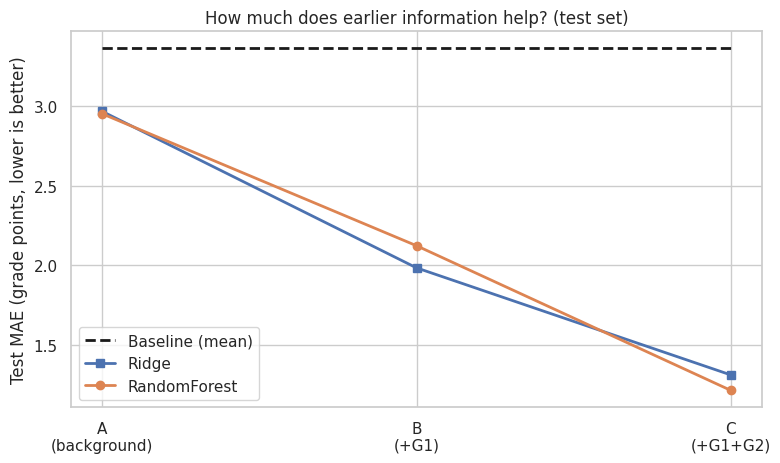

In [40]:
# ===== CELL 8.5 | "How Early?" Curve =====
# Purpose: Plot test MAE across scenarios A -> B -> C for each model.

fig, ax = plt.subplots(figsize=(8, 4.8))
labels = ["A\n(background)", "B\n(+G1)", "C\n(+G1+G2)"]
for name, style in [("Baseline (mean)", "k--"), ("Ridge", "s-"), ("RandomForest", "o-")]:
    vals = [test_results[(test_results.Scenario == sc) & (test_results.Model == name)]["MAE"].iloc[0]
            for sc in ["A", "B", "C"]]
    ax.plot(labels, vals, style, label=name, linewidth=2)
ax.set_ylabel("Test MAE (grade points, lower is better)")
ax.set_title("How much does earlier information help? (test set)")
ax.legend()
plt.tight_layout()
plt.savefig(FIG_DIR / "early_curve.png", dpi=150, bbox_inches="tight")
plt.show()

In [31]:
# ===== CELL 9.1 | Conformal Function (fixed) =====
# Purpose: Split-conformal quantile q = k-th smallest calibration error, k = ceil((n+1)(1-alpha)).

import math

def conformal_q(y_true, y_pred, alpha=ALPHA):
    scores = np.sort(np.abs(np.asarray(y_true) - np.asarray(y_pred)))
    n = len(scores)
    k = math.ceil((n + 1) * (1 - alpha))
    if k > n:
        return float("inf"), 1.0, n
    return float(scores[k - 1]), k / n, n

print("conformal_q ready")

conformal_q ready


In [32]:
# ===== CELL F.1 | Remove Outdated Conformal Checkpoints =====
# Purpose: Force 9.2 and 10.1 to recompute with the corrected q.

for f in ["q_values.json", "coverage_table.csv"] + [f"intervals_{s}.csv" for s in "ABC"]:
    (CKPT_DIR / f).unlink(missing_ok=True)
show_status()

File                                 Size (KB)
-----------------------------------------------
best_params.json                           0.9
cv_results.csv                             1.2
df_clean.csv                              41.0
feature_sets.json                          1.6
model_A.joblib                           565.5
model_B.joblib                           433.2
model_C.joblib                           432.4
preds_A.csv                                4.7
preds_B.csv                                4.7
preds_C.csv                                4.7
split_indices.json                         3.4
test_results.csv                           0.3


In [33]:
# ===== CELL 9.2 | Conformal Intervals (Checkpoint) =====
# Purpose: Get q from calibration predictions, build intervals for test students, save results.

if ckpt_exists("q_values.json") and all(ckpt_exists(f"intervals_{s}.csv") for s in "ABC"):
    q_values = ckpt_load("q_values.json")
else:
    q_values = {}
    for sc in ["A", "B", "C"]:
        saved = pd.read_csv(CKPT_DIR / f"preds_{sc}.csv")
        cal  = saved[saved["set"] == "calib"]
        test = saved[saved["set"] == "test"].copy()

        q, level, n = conformal_q(cal["y_true"], cal["y_pred"])
        q_values[sc] = {"q": q, "level": level, "n_calib": n}

        test["lower"] = (test["y_pred"] - q).clip(lower=0)
        test["upper"] = (test["y_pred"] + q).clip(upper=20)
        ckpt_save(test, f"intervals_{sc}.csv")
    ckpt_save(q_values, "q_values.json")

Saved: intervals_A.csv
Saved: intervals_B.csv
Saved: intervals_C.csv
Saved: q_values.json


In [34]:
# ===== CELL 9.3 | Summary of q and Interval Width =====
# Purpose: Show q per scenario and the average interval width on the test set.

rows = []
for sc in ["A", "B", "C"]:
    iv = pd.read_csv(CKPT_DIR / f"intervals_{sc}.csv")
    rows.append({"Scenario": sc,
                 "q": round(q_values[sc]["q"], 2),
                 "n_calib": q_values[sc]["n_calib"],
                 "quantile level": round(q_values[sc]["level"], 3),
                 "avg width (clipped)": round((iv["upper"] - iv["lower"]).mean(), 2)})
print(pd.DataFrame(rows).to_string(index=False))

Scenario    q  n_calib  quantile level  avg width (clipped)
       A 8.15       79           0.911                16.25
       B 3.79       79           0.911                 7.54
       C 2.99       79           0.911                 5.90


In [35]:
# ===== CELL 9.4 | Why Is q So Large? (Diagnostic) =====
# Purpose: Check whether the largest calibration errors belong to zero-grade students.

for sc in ["A", "B", "C"]:
    saved = pd.read_csv(CKPT_DIR / f"preds_{sc}.csv")
    cal = saved[saved["set"] == "calib"].copy()
    cal["abs_err"] = (cal["y_true"] - cal["y_pred"]).abs()
    top = cal.sort_values("abs_err", ascending=False).head(10)
    n_zero_in_top8 = int((top.head(8)["y_true"] == 0).sum())

    q_nonzero, _, _ = conformal_q(cal.loc[cal.y_true > 0, "y_true"],
                                  cal.loc[cal.y_true > 0, "y_pred"])
    print(f"Scenario {sc}: zero-grade students among the 8 largest errors = {n_zero_in_top8}/8 | "
          f"q (all) = {q_values[sc]['q']:.2f} | q (G3>0 only, for information) = {q_nonzero:.2f}")
    print(top[["y_true", "y_pred", "abs_err"]].round(2).head(10).to_string(index=False), "\n")

Scenario A: zero-grade students among the 8 largest errors = 8/8 | q (all) = 8.15 | q (G3>0 only, for information) = 5.46
 y_true  y_pred  abs_err
      0   12.74    12.74
      0   12.07    12.07
      0    9.79     9.79
      0    9.45     9.45
      0    9.35     9.35
      0    8.96     8.96
      0    8.54     8.54
      0    8.15     8.15
     19   11.63     7.37
     18   10.67     7.33 

Scenario B: zero-grade students among the 8 largest errors = 8/8 | q (all) = 3.79 | q (G3>0 only, for information) = 2.91
 y_true  y_pred  abs_err
      0    8.65     8.65
      0    8.39     8.39
      0    8.09     8.09
      0    6.18     6.18
      0    5.84     5.84
      0    5.28     5.28
      0    4.83     4.83
      0    3.79     3.79
     11    7.23     3.77
     10    6.25     3.75 

Scenario C: zero-grade students among the 8 largest errors = 6/8 | q (all) = 2.99 | q (G3>0 only, for information) = 2.07
 y_true  y_pred  abs_err
      0    8.40     8.40
      0    8.20     8.20
     

In [39]:
# ===== CELL 10.1 | Coverage Table =====
# Purpose: Measure empirical coverage and width on the test set, overall and by zero-grade status.

rows = []
for sc in ["A", "B", "C"]:
    iv = pd.read_csv(CKPT_DIR / f"intervals_{sc}.csv")
    inside = (iv["y_true"] >= iv["lower"]) & (iv["y_true"] <= iv["upper"])
    zero = iv["y_true"] == 0
    n = len(iv)
    rows.append({
        "Scenario": sc,
        "Target": 1 - ALPHA,
        "Coverage (all)": round(inside.mean(), 3),
        "Approx. SE": round(np.sqrt((1 - ALPHA) * ALPHA / n), 3),
        "Coverage (G3>0)": round(inside[~zero].mean(), 3),
        "Coverage (G3=0)": round(inside[zero].mean(), 3),
        "n zero-grade": int(zero.sum()),
        "Avg width": round((iv["upper"] - iv["lower"]).mean(), 2),
    })

coverage_table = pd.DataFrame(rows)
ckpt_save(coverage_table, "coverage_table.csv")
coverage_table.to_csv(RES_DIR / "coverage_table.csv", index=False)
print(coverage_table.to_string(index=False))

Saved: coverage_table.csv
Scenario  Target  Coverage (all)  Approx. SE  Coverage (G3>0)  Coverage (G3=0)  n zero-grade  Avg width
       A     0.9           0.911       0.034            1.000            0.000             7      16.25
       B     0.9           0.848       0.034            0.931            0.000             7       7.54
       C     0.9           0.924       0.034            0.972            0.429             7       5.90


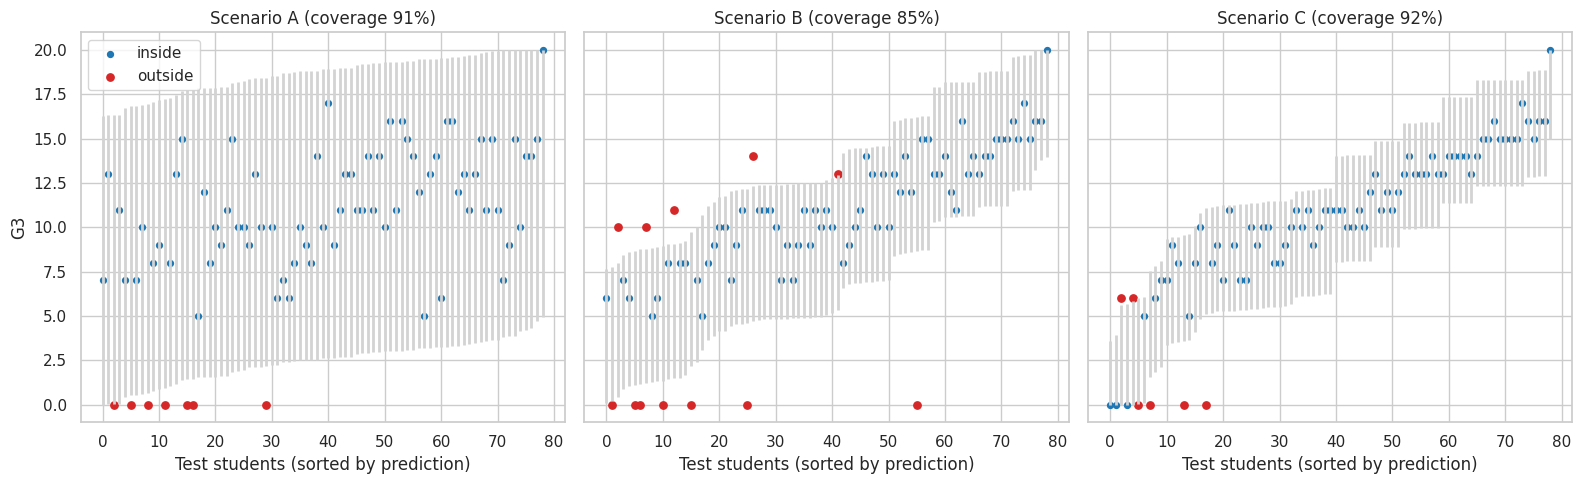

In [40]:
# ===== CELL 10.2 | Interval Plot =====
# Purpose: Visualise test intervals and which true grades fall inside or outside them.

fig, axes = plt.subplots(1, 3, figsize=(16, 5), sharey=True)
for ax, sc in zip(axes, ["A", "B", "C"]):
    iv = pd.read_csv(CKPT_DIR / f"intervals_{sc}.csv").sort_values("y_pred").reset_index(drop=True)
    inside = (iv["y_true"] >= iv["lower"]) & (iv["y_true"] <= iv["upper"])
    ax.vlines(iv.index, iv["lower"], iv["upper"], color="lightgray", linewidth=2)
    ax.scatter(iv.index[inside], iv["y_true"][inside], s=18, color="tab:blue", label="inside")
    ax.scatter(iv.index[~inside], iv["y_true"][~inside], s=28, color="tab:red", label="outside")
    ax.set_title(f"Scenario {sc} (coverage {inside.mean():.0%})")
    ax.set_xlabel("Test students (sorted by prediction)")
axes[0].set_ylabel("G3")
axes[0].legend()
plt.tight_layout()
plt.savefig(FIG_DIR / "intervals.png", dpi=150, bbox_inches="tight")
plt.show()

In [41]:
# ===== CELL 10.3 | Backup Zip =====
# Purpose: Refresh the backup with conformal results.

make_backup_zip("checkpoints_backup")
show_status()

Backup zip: /kaggle/working/checkpoints_backup.zip
File                                 Size (KB)
-----------------------------------------------
best_params.json                           0.9
coverage_table.csv                         0.2
cv_results.csv                             1.2
df_clean.csv                              41.0
feature_sets.json                          1.6
intervals_A.csv                            5.1
intervals_B.csv                            5.1
intervals_C.csv                            5.1
model_A.joblib                           565.5
model_B.joblib                           433.2
model_C.joblib                           432.4
preds_A.csv                                4.7
preds_B.csv                                4.7
preds_C.csv                                4.7
q_values.json                              0.3
split_indices.json                         3.4
test_results.csv                           0.3


In [42]:
# ===== CELL 10.4 | Multi-Seed Robustness (Resumable) =====
# Purpose: Repeat split -> fit -> conformal -> coverage for seeds 0-19; append results after every seed.

SEEDS = list(range(20))
MS_FILE = CKPT_DIR / "multiseed_partial.csv"

if FORCE_RERUN and MS_FILE.exists():
    MS_FILE.unlink()
done = set(pd.read_csv(MS_FILE)["seed"]) if MS_FILE.exists() else set()
print("Seeds already done:", sorted(done))

strata = (df[TARGET] == 0).astype(int)

for s in SEEDS:
    if s in done:
        continue
    tr, tmp = train_test_split(df.index, test_size=CALIB_FRAC + TEST_FRAC,
                               stratify=strata, random_state=s)
    ca, te = train_test_split(tmp, test_size=TEST_FRAC / (CALIB_FRAC + TEST_FRAC),
                              stratify=strata.loc[tmp], random_state=s)
    d_tr, d_ca, d_te = df.loc[tr], df.loc[ca], df.loc[te]

    rows = []
    for sc in ["A", "B", "C"]:
        X_tr, y_tr = get_xy(d_tr, sc)
        X_ca, y_ca = get_xy(d_ca, sc)
        X_te, y_te = get_xy(d_te, sc)
        pipe = make_pipeline(build_final_model(SELECTED[sc], sc), sc).fit(X_tr, y_tr)
        p_ca, p_te = pipe.predict(X_ca), pipe.predict(X_te)

        q, _, _ = conformal_q(y_ca, p_ca)
        lo = np.clip(p_te - q, 0, None)
        hi = np.clip(p_te + q, None, 20)
        yt = y_te.values
        inside = (yt >= lo) & (yt <= hi)
        zero = yt == 0

        rows.append({
            "seed": s, "scenario": sc,
            "test_mae": np.abs(yt - p_te).mean(),
            "baseline_mae": np.abs(yt - y_tr.mean()).mean(),
            "test_r2": r2_score(yt, p_te),
            "q": q,
            "coverage": inside.mean(),
            "coverage_pos": inside[~zero].mean(),
            "coverage_zero": inside[zero].mean() if zero.any() else np.nan,
            "n_zero": int(zero.sum()),
            "width": (hi - lo).mean(),
        })
    pd.DataFrame(rows).to_csv(MS_FILE, mode="a", header=not MS_FILE.exists(), index=False)
    print(f"Seed {s} done")

print("All seeds complete:", len(pd.read_csv(MS_FILE)["seed"].unique()), "seeds")

Seeds already done: []
Seed 0 done
Seed 1 done
Seed 2 done
Seed 3 done
Seed 4 done
Seed 5 done
Seed 6 done
Seed 7 done
Seed 8 done
Seed 9 done
Seed 10 done
Seed 11 done
Seed 12 done
Seed 13 done
Seed 14 done
Seed 15 done
Seed 16 done
Seed 17 done
Seed 18 done
Seed 19 done
All seeds complete: 20 seeds


In [43]:
# ===== CELL 10.5 | Multi-Seed Summary =====
# Purpose: Summarise stability of improvement over baseline and of conformal coverage across 20 splits.

ms = pd.read_csv(MS_FILE)
ms["improvement"] = ms["baseline_mae"] - ms["test_mae"]

summary = ms.groupby("scenario").agg(
    mae_mean=("test_mae", "mean"), mae_std=("test_mae", "std"),
    baseline_mae=("baseline_mae", "mean"),
    improve_mean=("improvement", "mean"),
    improve_pos_share=("improvement", lambda x: (x > 0).mean()),
    r2_mean=("test_r2", "mean"), r2_min=("test_r2", "min"),
    cov_mean=("coverage", "mean"), cov_std=("coverage", "std"),
    cov_min=("coverage", "min"), cov_max=("coverage", "max"),
    cov_pos_mean=("coverage_pos", "mean"),
    cov_zero_mean=("coverage_zero", "mean"),
    width_mean=("width", "mean"),
).round(3)

summary.to_csv(RES_DIR / "multiseed_summary.csv")
print(summary.T.to_string())

scenario                A      B      C
mae_mean            3.171  1.925  1.277
mae_std             0.190  0.115  0.142
baseline_mae        3.411  3.411  3.411
improve_mean        0.240  1.487  2.135
improve_pos_share   0.950  1.000  1.000
r2_mean             0.118  0.622  0.785
r2_min             -0.072  0.524  0.679
cov_mean            0.923  0.912  0.909
cov_std             0.022  0.025  0.031
cov_min             0.899  0.861  0.835
cov_max             0.975  0.962  0.962
cov_pos_mean        0.995  0.983  0.969
cov_zero_mean       0.186  0.179  0.293
width_mean         16.398  9.385  5.422


In [44]:
# ===== CELL 10.6 | Backup Zip =====
# Purpose: Refresh the backup with the multi-seed results.

make_backup_zip("checkpoints_backup")
show_status()

Backup zip: /kaggle/working/checkpoints_backup.zip
File                                 Size (KB)
-----------------------------------------------
best_params.json                           0.9
coverage_table.csv                         0.2
cv_results.csv                             1.2
df_clean.csv                              41.0
feature_sets.json                          1.6
intervals_A.csv                            5.1
intervals_B.csv                            5.1
intervals_C.csv                            5.1
model_A.joblib                           565.5
model_B.joblib                           433.2
model_C.joblib                           432.4
multiseed_partial.csv                      8.6
preds_A.csv                                4.7
preds_B.csv                                4.7
preds_C.csv                                4.7
q_values.json                              0.3
split_indices.json                         3.4
test_results.csv                           0.3


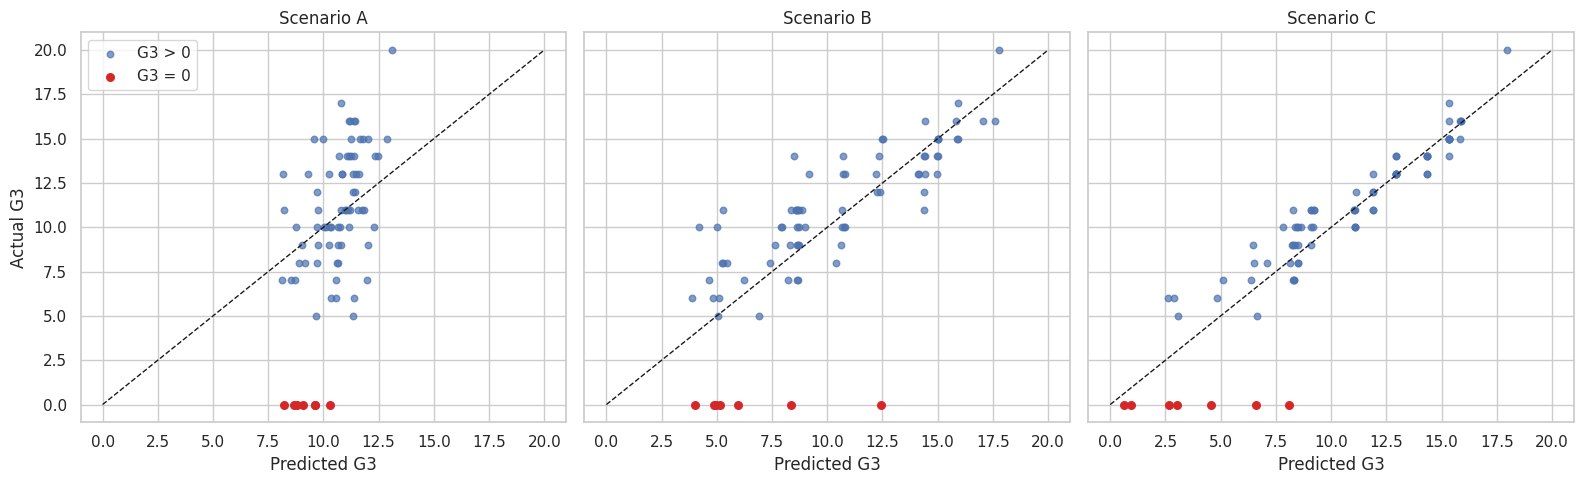

In [45]:
# ===== CELL 11.1 | Actual vs Predicted =====
# Purpose: Compare predicted and true G3 on the test set; zero-grade students are marked in red.

fig, axes = plt.subplots(1, 3, figsize=(16, 5), sharex=True, sharey=True)
for ax, sc in zip(axes, ["A", "B", "C"]):
    t = pd.read_csv(CKPT_DIR / f"preds_{sc}.csv").query("set == 'test'")
    zero = t["y_true"] == 0
    ax.scatter(t.loc[~zero, "y_pred"], t.loc[~zero, "y_true"], s=22, alpha=0.7, label="G3 > 0")
    ax.scatter(t.loc[zero, "y_pred"], t.loc[zero, "y_true"], s=30, color="tab:red", label="G3 = 0")
    ax.plot([0, 20], [0, 20], "k--", linewidth=1)
    ax.set_title(f"Scenario {sc}")
    ax.set_xlabel("Predicted G3")
axes[0].set_ylabel("Actual G3")
axes[0].legend()
plt.tight_layout()
plt.savefig(FIG_DIR / "actual_vs_pred.png", dpi=150, bbox_inches="tight")
plt.show()

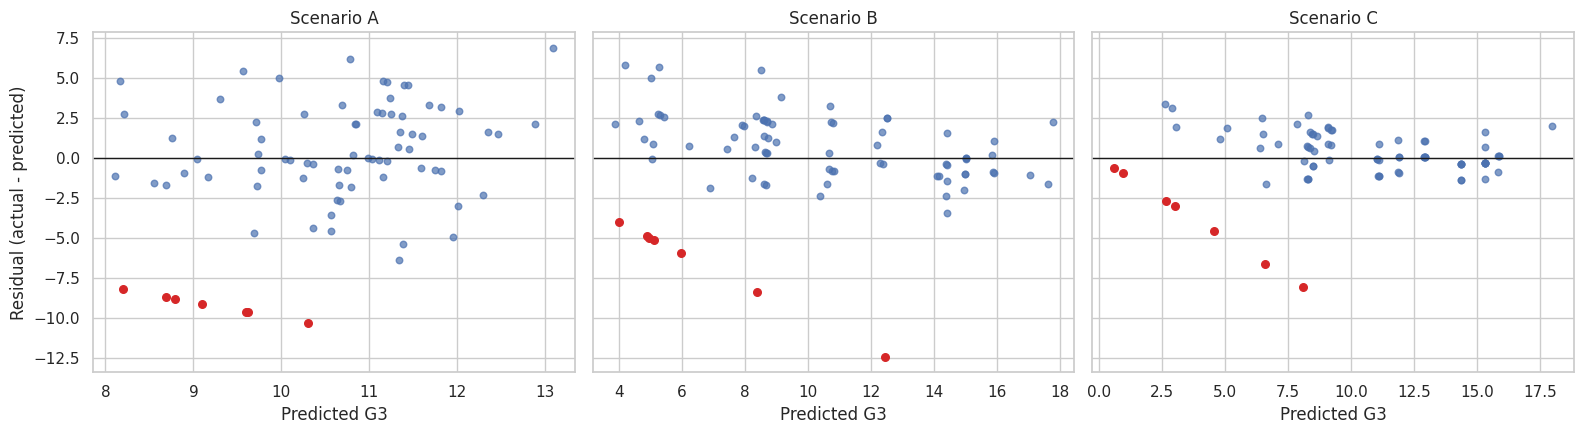

In [46]:
# ===== CELL 11.2 | Residual Plot =====
# Purpose: Check for patterns in residuals (actual - predicted) on the test set.

fig, axes = plt.subplots(1, 3, figsize=(16, 4.5), sharey=True)
for ax, sc in zip(axes, ["A", "B", "C"]):
    t = pd.read_csv(CKPT_DIR / f"preds_{sc}.csv").query("set == 'test'")
    res = t["y_true"] - t["y_pred"]
    zero = t["y_true"] == 0
    ax.scatter(t.loc[~zero, "y_pred"], res[~zero], s=22, alpha=0.7)
    ax.scatter(t.loc[zero, "y_pred"], res[zero], s=30, color="tab:red")
    ax.axhline(0, color="k", linewidth=1)
    ax.set_title(f"Scenario {sc}")
    ax.set_xlabel("Predicted G3")
axes[0].set_ylabel("Residual (actual - predicted)")
plt.tight_layout()
plt.savefig(FIG_DIR / "residuals.png", dpi=150, bbox_inches="tight")
plt.show()

Loaded from checkpoint: model_A.joblib
Loaded from checkpoint: model_B.joblib
Loaded from checkpoint: model_C.joblib


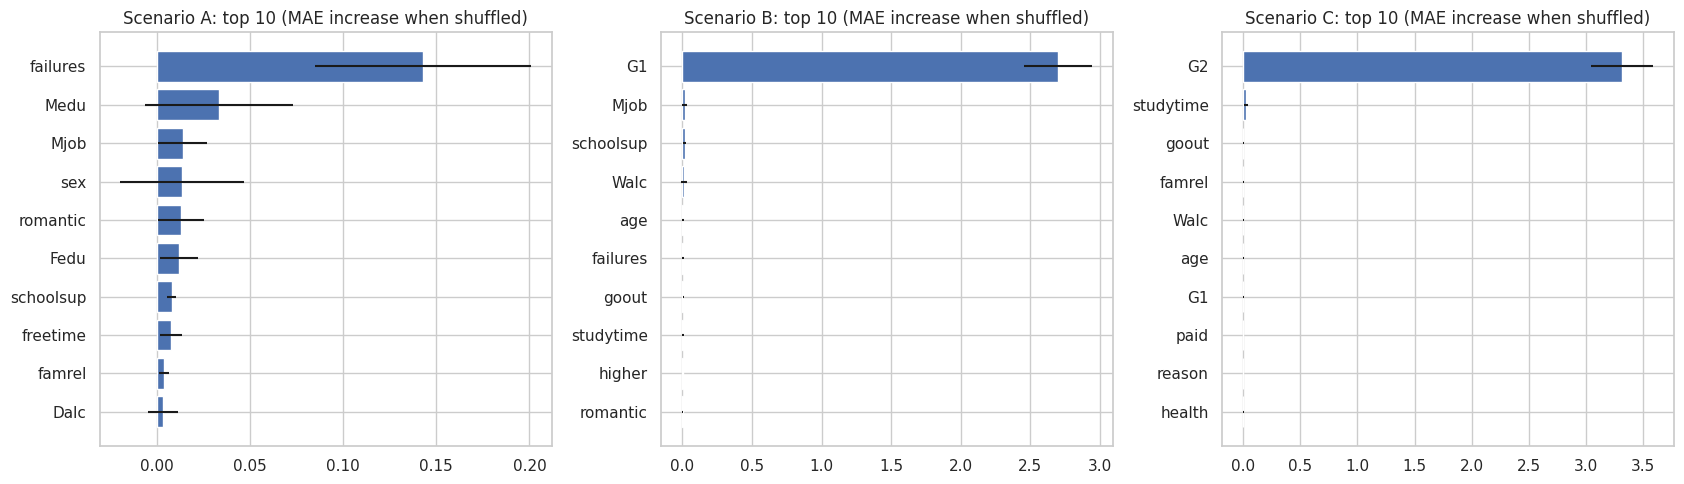

A  feature  mae_increase
failures         0.143
    Medu         0.033
    Mjob         0.014
     sex         0.013
romantic         0.013 

B   feature  mae_increase
       G1         2.698
     Mjob         0.017
schoolsup         0.015
     Walc         0.013
      age         0.004 

C   feature  mae_increase
       G2         3.316
studytime         0.025
    goout         0.004
   famrel         0.003
     Walc         0.003 



In [47]:
# ===== CELL 11.3 | Permutation Importance =====
# Purpose: Measure how much MAE rises when each original feature is shuffled (calibration set, 30 repeats).

from sklearn.inspection import permutation_importance

imp_rows = []
fig, axes = plt.subplots(1, 3, figsize=(17, 5))
for ax, sc in zip(axes, ["A", "B", "C"]):
    pipe = ckpt_load(f"model_{sc}.joblib")
    X_ca, y_ca = get_xy(df_calib, sc)
    r = permutation_importance(pipe, X_ca, y_ca, scoring="neg_mean_absolute_error",
                               n_repeats=30, random_state=SEED)
    imp = pd.DataFrame({"feature": X_ca.columns, "mae_increase": r.importances_mean,
                        "std": r.importances_std, "scenario": sc})
    imp_rows.append(imp)
    top = imp.nlargest(10, "mae_increase").iloc[::-1]
    ax.barh(top["feature"], top["mae_increase"], xerr=top["std"])
    ax.set_title(f"Scenario {sc}: top 10 (MAE increase when shuffled)")
plt.tight_layout()
plt.savefig(FIG_DIR / "perm_importance.png", dpi=150, bbox_inches="tight")
plt.show()

imp_all = pd.concat(imp_rows)
imp_all.to_csv(RES_DIR / "permutation_importance.csv", index=False)
for sc in ["A", "B", "C"]:
    print(sc, imp_all[imp_all.scenario == sc].nlargest(5, "mae_increase")[["feature", "mae_increase"]]
          .round(3).to_string(index=False), "\n")

In [48]:
# ===== CELL 11.4 | Error Analysis =====
# Purpose: Split test MAE by zero-grade status and list the largest errors per scenario.

rows, worst = [], []
for sc in ["A", "B", "C"]:
    t = pd.read_csv(CKPT_DIR / f"preds_{sc}.csv").query("set == 'test'").copy()
    t["abs_err"] = (t["y_true"] - t["y_pred"]).abs()
    zero = t["y_true"] == 0
    rows.append({"Scenario": sc,
                 "MAE all": round(t["abs_err"].mean(), 2),
                 "MAE G3>0": round(t.loc[~zero, "abs_err"].mean(), 2),
                 "MAE G3=0": round(t.loc[zero, "abs_err"].mean(), 2),
                 "n G3>0": int((~zero).sum()), "n G3=0": int(zero.sum())})
    worst.append(t.assign(scenario=sc).nlargest(8, "abs_err")[["scenario", "row_id", "y_true", "y_pred", "abs_err"]])

print(pd.DataFrame(rows).to_string(index=False))
worst = pd.concat(worst).round(2)
worst.to_csv(RES_DIR / "worst_predictions.csv", index=False)
print("\nLargest test errors:")
print(worst.to_string(index=False))

Scenario  MAE all  MAE G3>0  MAE G3=0  n G3>0  n G3=0
       A     2.95      2.34      9.19      72       7
       B     2.12      1.69      6.53      72       7
       C     1.21      0.96      3.78      72       7

Largest test errors:
scenario  row_id  y_true  y_pred  abs_err
       A     333       0   10.30    10.30
       A     168       0    9.62     9.62
       A     162       0    9.60     9.60
       A     383       0    9.10     9.10
       A     130       0    8.80     8.80
       A     160       0    8.69     8.69
       A     128       0    8.20     8.20
       A      47      20   13.09     6.91
       B     130       0   12.43    12.43
       B     333       0    8.37     8.37
       B     162       0    5.96     5.96
       B       4      10    4.19     5.81
       B      40      11    5.28     5.72
       B     102      14    8.51     5.49
       B     128       0    5.13     5.13
       B     219      10    5.01     4.99
       C     333       0    8.09     8.09
      

In [49]:
# ===== CELL 11.5 | Full Backup Zip =====
# Purpose: Zip checkpoints + figures + results together (the earlier backup had checkpoints only).

def make_full_backup(name="project_outputs"):
    tmp = BASE_DIR / "_bundle"
    if tmp.exists():
        shutil.rmtree(tmp)
    for d in (CKPT_DIR, FIG_DIR, RES_DIR):
        shutil.copytree(d, tmp / d.name)
    out = shutil.make_archive(str(BASE_DIR / name), "zip", tmp)
    shutil.rmtree(tmp)
    print("Full backup:", out)

make_full_backup()
make_backup_zip("checkpoints_backup")

Full backup: /kaggle/working/project_outputs.zip
Backup zip: /kaggle/working/checkpoints_backup.zip


In [50]:
# ===== CELL 12.1 | Summary Table =====
# Purpose: Combine seed-42 and 20-split results into one table for the README and CV.

ms = pd.read_csv(MS_FILE)
g = ms.groupby("scenario")
tr  = test_results[test_results.Selected == "yes"].set_index("Scenario")
base = test_results[test_results.Model == "Baseline (mean)"].set_index("Scenario")
cov = pd.read_csv(CKPT_DIR / "coverage_table.csv").set_index("Scenario")

summary_all = pd.DataFrame({
    "Model": pd.Series(SELECTED),
    "S42 baseline MAE": base["MAE"],
    "S42 test MAE": tr["MAE"],
    "S42 test R2": tr["R2"],
    "S42 q": pd.Series({k: v["q"] for k, v in q_values.items()}),
    "S42 coverage": cov["Coverage (all)"],
    "S42 width": cov["Avg width"],
    "20-split MAE": g["test_mae"].mean(),
    "20-split R2": g["test_r2"].mean(),
    "20-split coverage": g["coverage"].mean(),
    "20-split cov G3=0": g["coverage_zero"].mean(),
    "20-split width": g["width"].mean(),
}).round(3)

summary_all.to_csv(RES_DIR / "summary.csv")
print(summary_all.T.to_string())

                              A             B             C
Model              RandomForest  RandomForest  RandomForest
S42 baseline MAE          3.361         3.361         3.361
S42 test MAE               2.95         2.122         1.214
S42 test R2               0.208          0.56         0.832
S42 q                     8.151         3.794         2.989
S42 coverage              0.911         0.848         0.924
S42 width                 16.25          7.54           5.9
20-split MAE              3.171         1.925         1.277
20-split R2               0.118         0.622         0.785
20-split coverage         0.923         0.912         0.909
20-split cov G3=0         0.186         0.179         0.293
20-split width           16.398         9.385         5.422


In [52]:
# ===== CELL 12.2 | Requirements =====
# Purpose: Save the library versions used in this notebook.

import matplotlib
reqs = [f"pandas=={pd.__version__}", f"numpy=={np.__version__}",
        f"scikit-learn=={sklearn.__version__}", f"matplotlib=={matplotlib.__version__}",
        f"seaborn=={sns.__version__}", f"joblib=={joblib.__version__}"]
(BASE_DIR / "requirements.txt").write_text("\n".join(reqs) + "\n")
print("\n".join(reqs))

pandas==2.3.3
numpy==2.1.3
scikit-learn==1.6.1
matplotlib==3.10.0
seaborn==0.13.2
joblib==1.6.0


In [53]:
# ===== CELL 12.3 | Final Backup Zip =====
# Purpose: Bundle checkpoints, figures and results (including summary.csv) for download.

make_full_backup()
make_backup_zip("checkpoints_backup")

Full backup: /kaggle/working/project_outputs.zip
Backup zip: /kaggle/working/checkpoints_backup.zip
